# Case Study 01 – Loan Prediction Preprocessing

## Step 1: Loading and Understanding the Dataset

**Objective:** Load the loan prediction dataset and examine its structure, data types and missing values.

In [10]:
from google.colab import files

uploaded = files.upload()

Saving train_loan.csv to train_loan (2).csv


In [11]:
import pandas as pd
import numpy as np

# Load the loan prediction dataset
df = pd.read_csv("train_loan.csv")

# Display the first five rows
print("First 5 rows of the dataset:")
display(df.head())

# Display dataset dimensions
print("Dataset Shape:", df.shape)

First 5 rows of the dataset:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


Dataset Shape: (614, 13)


In [12]:
# Display dataset information
print("Dataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB

Statistical Summary:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000



Missing Values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


## Step 2: Missing Value Handling

Missing values can affect data analysis and machine learning performance.

Categorical columns are filled using the mode (most frequent value), while LoanAmount is filled using the median to reduce the influence of extreme values.

In [13]:
# Step 2: Missing Value Handling

# Create a copy of the original dataset
df_cleaned = df.copy()

# Display missing values before handling
print("Missing Values Before Handling:")
print(df_cleaned.isnull().sum())

# Fill categorical and discrete columns using mode
mode_columns = [
    "Gender",
    "Married",
    "Dependents",
    "Self_Employed",
    "Loan_Amount_Term",
    "Credit_History"
]

for column in mode_columns:
    df_cleaned[column] = df_cleaned[column].fillna(
        df_cleaned[column].mode()[0]
    )

# Fill LoanAmount using median
df_cleaned["LoanAmount"] = df_cleaned["LoanAmount"].fillna(
    df_cleaned["LoanAmount"].median()
)

# Check missing values after handling
print("\nMissing Values After Handling:")
print(df_cleaned.isnull().sum())

# Verify dataset shape
print("\nDataset Shape:", df_cleaned.shape)

Missing Values Before Handling:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Missing Values After Handling:
Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

Dataset Shape: (614, 13)


### Explanation – Missing Value Handling

The loan prediction dataset was examined to identify missing values using the `isnull().sum()` function.

A total of 149 missing values were identified across seven columns.

The missing values in Gender, Married, Dependents, Self_Employed, Loan_Amount_Term, and Credit_History were replaced using the mode of their respective columns.

The missing values in LoanAmount were replaced using the median because the median is less sensitive to extreme values than the mean.

A copy of the original dataset was created to preserve the original data.

After preprocessing, all missing values were handled successfully, and the dataset retained its original shape of 614 rows and 13 columns.

## Step 3: Outlier Detection

Outliers are unusually high or low values in a dataset.

The Interquartile Range (IQR) method is used to detect potential outliers in ApplicantIncome, CoapplicantIncome, and LoanAmount.

In [14]:
# Step 3: Outlier Detection using IQR

outlier_columns = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount"
]

for column in outlier_columns:

    Q1 = df_cleaned[column].quantile(0.25)
    Q3 = df_cleaned[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_cleaned[
        (df_cleaned[column] < lower_bound) |
        (df_cleaned[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} outliers detected")

ApplicantIncome: 50 outliers detected
CoapplicantIncome: 18 outliers detected
LoanAmount: 41 outliers detected


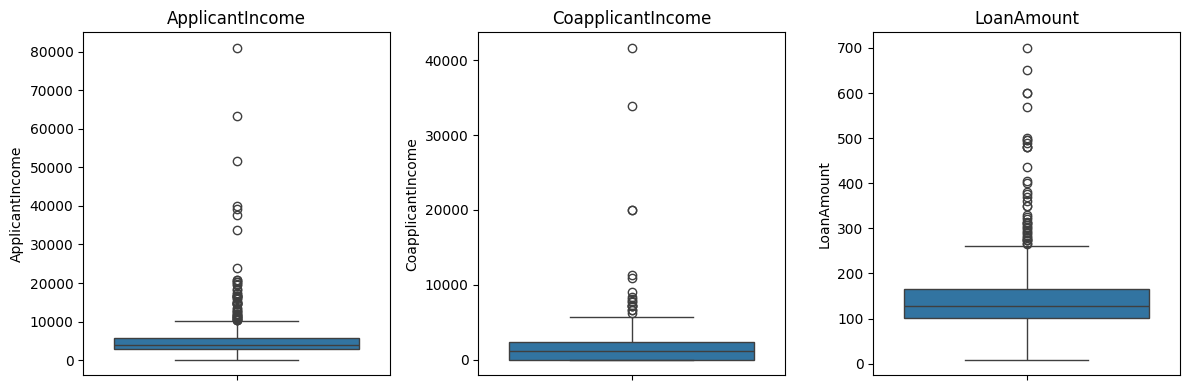

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 4))

for i, column in enumerate(outlier_columns, 1):

    plt.subplot(1, 3, i)
    sns.boxplot(y=df_cleaned[column])
    plt.title(column)

plt.tight_layout()
plt.show()

### Explanation – Outlier Detection

Outliers were detected using the Interquartile Range (IQR) method.

The first quartile (Q1) represents the 25th percentile, while the third quartile (Q3) represents the 75th percentile.

IQR = Q3 − Q1

Lower Bound = Q1 − 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Values outside these boundaries were identified as potential outliers.

Boxplots were created to visualize the distribution of numerical features and identify extreme values.

The outliers were retained at this stage because unusually high incomes or loan amounts may represent genuine loan applications. Removing them without further investigation could result in information loss.

## Step 4: Encoding Categorical Variables

Encoding converts categorical values into numerical representations suitable for machine learning.

In [16]:
# Step 4: Encoding Categorical Variables

import pandas as pd

# Create a copy of the cleaned dataset
df_encoded = df_cleaned.copy()

# Remove Loan_ID because it is only an identifier
df_encoded = df_encoded.drop(columns=["Loan_ID"])

# Encode the target variable
df_encoded["Loan_Status"] = df_encoded["Loan_Status"].map({
    "N": 0,
    "Y": 1
})

# One-hot encode categorical input features
categorical_columns = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Property_Area"
]

df_encoded = pd.get_dummies(
    df_encoded,
    columns=categorical_columns,
    dtype=int
)

print("Dataset After Encoding:")
display(df_encoded.head())

print("\nDataset Shape:", df_encoded.shape)

print("\nRemaining Text Columns:")
print(df_encoded.select_dtypes(include="object").columns.tolist())

Dataset After Encoding:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_Female,Gender_Male,Married_No,Married_Yes,...,Dependents_1,Dependents_2,Dependents_3+,Education_Graduate,Education_Not Graduate,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,5849,0.0,128.0,360.0,1.0,1,0,1,1,0,...,0,0,0,1,0,1,0,0,0,1
1,4583,1508.0,128.0,360.0,1.0,0,0,1,0,1,...,1,0,0,1,0,1,0,1,0,0
2,3000,0.0,66.0,360.0,1.0,1,0,1,0,1,...,0,0,0,1,0,0,1,0,0,1
3,2583,2358.0,120.0,360.0,1.0,1,0,1,0,1,...,0,0,0,0,1,1,0,0,0,1
4,6000,0.0,141.0,360.0,1.0,1,0,1,1,0,...,0,0,0,1,0,1,0,0,0,1



Dataset Shape: (614, 21)

Remaining Text Columns:
[]


### Explanation – Encoding

Categorical variables contain text values that must be converted into numerical form before being used by many machine learning algorithms.

The Loan_ID column was removed because it is a unique identifier and does not provide meaningful predictive information.

The target variable Loan_Status was converted into binary values, where N represents 0 and Y represents 1.

One-hot encoding was applied to categorical input features using the Pandas get_dummies() function.

One-hot encoding creates separate binary columns for each category without assuming an artificial numerical order between categories.

After encoding, the dataset contains numerical values suitable for further preprocessing.

## Step 5: Feature Scaling

Feature scaling is used to standardize numerical variables so that they have comparable scales.

StandardScaler is applied to continuous numerical features.

In [17]:
# Step 5: Feature Scaling

from sklearn.preprocessing import StandardScaler

# Create a copy of the encoded dataset
df_scaled = df_encoded.copy()

# Select numerical columns for scaling
scale_columns = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term"
]

# Initialize StandardScaler
scaler = StandardScaler()

# Apply scaling
df_scaled[scale_columns] = scaler.fit_transform(
    df_scaled[scale_columns]
)

# Display the scaled dataset
print("Dataset After Scaling:")
display(df_scaled.head())

# Check mean and standard deviation
print("\nMean After Scaling:")
print(df_scaled[scale_columns].mean().round(2))

print("\nStandard Deviation After Scaling:")
print(df_scaled[scale_columns].std(ddof=0).round(2))

# Check dataset shape
print("\nFinal Dataset Shape:", df_scaled.shape)

Dataset After Scaling:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_Female,Gender_Male,Married_No,Married_Yes,...,Dependents_1,Dependents_2,Dependents_3+,Education_Graduate,Education_Not Graduate,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,0.072991,-0.554487,-0.211241,0.273231,1.0,1,0,1,1,0,...,0,0,0,1,0,1,0,0,0,1
1,-0.134412,-0.038732,-0.211241,0.273231,1.0,0,0,1,0,1,...,1,0,0,1,0,1,0,1,0,0
2,-0.393747,-0.554487,-0.948996,0.273231,1.0,1,0,1,0,1,...,0,0,0,1,0,0,1,0,0,1
3,-0.462062,0.251980,-0.306435,0.273231,1.0,1,0,1,0,1,...,0,0,0,0,1,1,0,0,0,1
4,0.097728,-0.554487,-0.056551,0.273231,1.0,1,0,1,1,0,...,0,0,0,1,0,1,0,0,0,1



Mean After Scaling:
ApplicantIncome     -0.0
CoapplicantIncome    0.0
LoanAmount          -0.0
Loan_Amount_Term     0.0
dtype: float64

Standard Deviation After Scaling:
ApplicantIncome      1.0
CoapplicantIncome    1.0
LoanAmount           1.0
Loan_Amount_Term     1.0
dtype: float64

Final Dataset Shape: (614, 21)


### Explanation – Feature Scaling

Feature scaling was performed using StandardScaler from the Scikit-learn library.

Four numerical features were selected: ApplicantIncome, CoapplicantIncome, LoanAmount, and Loan_Amount_Term.

StandardScaler transforms numerical values by subtracting the mean and dividing by the standard deviation.

After scaling, the selected features have a mean close to 0 and a standard deviation close to 1.

Categorical features, Credit_History, and the target variable Loan_Status were not scaled.

The final preprocessed dataset contains 614 rows and 21 columns.

## Conclusion

In this case study, the Loan Prediction dataset was successfully loaded and preprocessed using Python.

The dataset originally contained 614 rows and 13 columns.

The following preprocessing techniques were performed:

1. **Missing Value Handling:** A total of 149 missing values were handled using median and mode imputation.
2. **Outlier Detection:** Potential outliers were identified in ApplicantIncome, CoapplicantIncome, and LoanAmount using the Interquartile Range (IQR) method and visualized using boxplots. These values were retained to avoid unnecessary information loss.
3. **Encoding:** Categorical variables were converted into numerical representations using one-hot encoding, and Loan_Status was converted into binary values.
4. **Feature Scaling:** StandardScaler was applied to selected numerical features to standardize their values.

After preprocessing, the final dataset contained **614 rows and 21 columns**, with no missing values.

The case study demonstrates how preprocessing improves data consistency and prepares a dataset for machine learning applications.

**Note:** For actual predictive modeling, preprocessing transformations should be fitted using training data only to prevent data leakage.